# 02 — Plan transitions: who upgrades from Basic, who downgrades, and why Basic upgrades fell in 2026

**Revenue Analytics · data as of 30 Sep 2026 · synthetic data** (see `docs/data_model.md`)
Request: *"Expansion clearly slowed last quarter — why?"* — the plan-upgrade part of the answer (`docs/01_request_and_scope.md`, Q2 (d)(e)); input to the Product / Pricing decision on the April 2026 Basic packaging change and to Growth Marketing's 2027 Paid Social plan (scope §3).

In [1]:
from saas_rev import marts, theme
from saas_rev.nbutil import md, setup, show
from saas_rev.analysis import transitions as T
from saas_rev.theme import money, pct, pts
import pandas as pd
setup()
k = T.key_numbers()

## TL;DR

In [2]:
t12, t12p = k['transition_12m_basic'], k['transition_12m_premium']
s12, s24 = k['basic_signups_state_12m'], k['basic_signups_state_24m']
d12 = k['downgrades_last_12m_by_source']
ttu, chu = k['time_to_upgrade_12m_by_channel'], k['churn_12m_by_channel']
raw, step, trig = k['upgrade_rate_non_ps_change_pts'], k['non_ps_step_net_of_trend_pts'], k['product_trigger_threshold_rel']
pp0 = marts.load('transitions__upgrade_rate_pre_post')
dim_names = {'acquisition_channel': 'channel', 'segment': 'segment', 'tenure_band': 'tenure band', 'billing_period': 'billing period'}
down_in = [n for d, n in dim_names.items() if (pp0[pp0.dimension == d].change_pts < 0).all()]
down_txt = (', '.join(down_in[:-1]) + ' and ' + down_in[-1]) if len(down_in) > 1 else ''.join(down_in)
both_past = k['upgrade_rate_controlled_rel_change'] <= trig and k['non_ps_step_net_of_trend_rel'] <= trig
churn_zero = k['basic_churn_non_ps_change_lo'] < 0 < k['basic_churn_non_ps_change_hi']
md(f"""
- **The Basic → Premium upgrade rate fell {pct(-k['upgrade_rate_rel_change'], 0)} in 2026.** {pct(k['upgrade_rate_pre'], 2)} per month in {k['pre_window']} → {pct(k['upgrade_rate_post'], 2)} in {k['post_window']}.
  Paid Social excluded: {pct(k['upgrade_rate_non_ps_pre'], 2)} → {pct(k['upgrade_rate_non_ps_post'], 2)} ({pts(raw, 2)}, 95%: {pts(k['upgrade_rate_non_ps_change_lo'], 2)} to {pts(k['upgrade_rate_non_ps_change_hi'], 2)}).
- **Channel mix explains little of it.** Paid Social grew from {pct(k['paid_social_share_basic_base_pre'], 1)} to {pct(k['paid_social_share_basic_base_post'], 1)} of the Basic base, but its mix effect is only {pts(k['mix_effect_pts_shapley'], 2)} of the {pts(k['upgrade_rate_change_pts'], 2)} fall
  ({pct(k['mix_share_of_change'], 0)}; between {pts(k['mix_effect_pts_at_post_rates'], 2)} and {pts(k['mix_effect_pts_at_pre_rates'], 2)} depending on the ordering). {('Within-group rates fell in every ' + down_txt + '.') if down_in else ''}
- **The fall lines up with the April packaging change, but part of it was under way before.** Non-Paid-Social upgrades were already drifting down inside the pre window ({pts(k['non_ps_pre_trend_slope_pts_per_month'], 3)} per month); {abs(step) * 100:.2f} of the {abs(raw) * 100:.2f}-point fall is beyond that trend ({pct(k['non_ps_step_net_of_trend_rel'], 0)} against the extended trend), and the three months before vs after April are {pct(k['non_ps_rate_jan_mar_2026'], 2)} → {pct(k['non_ps_rate_may_jul_2026'], 2)}.
  So the part of the fall that coincides with the change is {abs(step) * 100:.1f} to {abs(k['non_ps_step_from_pre_april_level_pts']) * 100:.1f} points a month — {abs(step) * 100:.1f} if the earlier drift had continued, {abs(k['non_ps_step_from_pre_april_level_pts']) * 100:.1f} if the rate had held at its pre-April level ({pct(k['non_ps_pre_trend_level_end_of_march'], 2)}); the {abs(raw) * 100:.2f}-point fall against the 12-month pre-window average includes the drift and is not a measure of the change. A range, not a measured effect. Controlled for Paid Social and Technology the rate is {pct(k['upgrade_rate_controlled_rel_change'], 0)} vs pre, and net of the earlier trend (Paid Social excluded) {pct(k['non_ps_step_net_of_trend_rel'], 0)}: {'both past' if both_past else 'not both past'} the Product trigger ({pct(trig, 0)}). Observational; the clean test is a holdout.
- **The retention gain is small{' and not distinguishable from zero' if churn_zero else ''}.** Basic logo churn (non-Paid-Social) {pct(k['basic_churn_non_ps_may_sep_2025'], 2)} → {pct(k['basic_churn_non_ps_may_sep_2026'], 2)} per month ({pts(k['basic_churn_non_ps_change_pts'], 2)}, 95%: {pts(k['basic_churn_non_ps_change_lo'], 2)} to {pts(k['basic_churn_non_ps_change_hi'], 2)}).
  Sized as if the whole before / after difference were due to the packaging change: {money(k['foregone_upgrade_mrr_per_month'])} a month of upgrade MRR against {money(k['retained_basic_mrr_per_month'])} of Basic MRR kept = **{money(k['net_mrr_per_month'])} a month** (range {money(k['net_mrr_lo'])} to {money(k['net_mrr_hi'])}; {money(k['net_mrr_per_month_trend_adjusted'])} trend-adjusted), about {money(k['net_mrr_12m_run_rate'])} after 12 months against {money(k['basic_mrr_sep_2026'])} of Basic MRR.
- **Flows.** Of Basic signups, {pct(s12.get('premium', 0) + s12.get('enterprise', 0), 0)} are on a higher plan 12 months later and {pct(s12.get('churned', 0), 0)} have churned. Counted over every Basic account-month (tenured accounts included), {pct(t12['premium'] + t12['enterprise'], 0)} moved up and {pct(t12['churned'], 0)} churned within 12 months; Premium account-months: {pct(t12p['premium'], 0)} still Premium, {pct(t12p['basic'], 0)} on Basic, {pct(t12p['churned'], 0)} churned.
- **Downgrades.** {k['downgrades_last_12m']} in the last 12 months ({k['downgrades_last_12m_premium_to_basic']} Premium → Basic, {k['downgrades_last_12m_enterprise_to_premium']} Enterprise → Premium) vs {k['downgrades_prior_12m']} in the 12 before, while the rate per Premium / Enterprise account-month went {pct(k['downgrade_rate_prior_12m'], 2)} → {pct(k['downgrade_rate_last_12m'], 2)}: {'the count rose with the base, not the rate' if k['downgrade_rate_last_12m'] <= k['downgrade_rate_prior_12m'] else 'the rate rose too'}. {d12.get('customer_success', 0)} CS saves, {d12.get('self_serve', 0)} self-serve, {d12.get('renewal', 0)} at renewal; they keep {pct(k['downgrades_last_12m_mrr_retained_share'], 0)} of their MRR.
  {pct(k['cs_save_paying_6m_share'], 0)} of CS-saved accounts still pay 6 months later (95%: {pct(k['cs_save_paying_6m_lo'], 0)}–{pct(k['cs_save_paying_6m_hi'], 0)}; n = {k['cs_save_downgrades_observed_6m']}) vs {pct(k['cs_save_comparable_paying_6m_share'], 0)} of comparable accounts.
- **Time to upgrade.** By month 12, {pct(ttu['Outbound Sales'], 0)} of Outbound Sales and {pct(ttu['Partner'], 0)} of Partner Basic signups have upgraded vs {pct(ttu['Paid Social'], 0)} of Paid Social — where {pct(chu['Paid Social'], 0)} have churned by then.
""")


- **The Basic → Premium upgrade rate fell 55% in 2026.** 1.51% per month in Apr 2025 - Mar 2026 → 0.69% in May 2026 - Sep 2026.
  Paid Social excluded: 1.60% → 0.77% (−0.83 pts, 95%: −1.10 pts to −0.55 pts).
- **Channel mix explains little of it.** Paid Social grew from 10.4% to 16.6% of the Basic base, but its mix effect is only −0.04 pts of the −0.83 pts fall
  (4%; between −0.03 pts and −0.05 pts depending on the ordering). Within-group rates fell in every channel, segment, tenure band and billing period.
- **The fall lines up with the April packaging change, but part of it was under way before.** Non-Paid-Social upgrades were already drifting down inside the pre window (−0.050 pts per month); 0.38 of the 0.83-point fall is beyond that trend (−33% against the extended trend), and the three months before vs after April are 1.46% → 0.82%.
  So the part of the fall that coincides with the change is 0.4 to 0.6 points a month — 0.4 if the earlier drift had continued, 0.6 if the rate had held at its pre-April level (1.35%); the 0.83-point fall against the 12-month pre-window average includes the drift and is not a measure of the change. A range, not a measured effect. Controlled for Paid Social and Technology the rate is −51% vs pre, and net of the earlier trend (Paid Social excluded) −33%: both past the Product trigger (−20%). Observational; the clean test is a holdout.
- **The retention gain is small and not distinguishable from zero.** Basic logo churn (non-Paid-Social) 1.93% → 1.79% per month (−0.14 pts, 95%: −0.62 pts to +0.31 pts).
  Sized as if the whole before / after difference were due to the packaging change: −$3.1K a month of upgrade MRR against $356 of Basic MRR kept = **−$2.7K a month** (range −$4.8K to −$475; −$1.0K trend-adjusted), about −$32.4K after 12 months against $317K of Basic MRR.
- **Flows.** Of Basic signups, 13% are on a higher plan 12 months later and 25% have churned. Counted over every Basic account-month (tenured accounts included), 13% moved up and 22% churned within 12 months; Premium account-months: 80% still Premium, 5% on Basic, 14% churned.
- **Downgrades.** 82 in the last 12 months (75 Premium → Basic, 7 Enterprise → Premium) vs 49 in the 12 before, while the rate per Premium / Enterprise account-month went 0.59% → 0.51%: the count rose with the base, not the rate. 34 CS saves, 32 self-serve, 16 at renewal; they keep 44% of their MRR.
  91% of CS-saved accounts still pay 6 months later (95%: 78%–96%; n = 43) vs 93% of comparable accounts.
- **Time to upgrade.** By month 12, 18% of Outbound Sales and 17% of Partner Basic signups have upgraded vs 5% of Paid Social — where 48% have churned by then.


## Question
1. Where do customers on each plan end up 6 / 12 / 24 months later, including churn?
2. Who upgrades from Basic — by segment, channel, industry, tenure and billing period — and how has the rate moved over time?
3. Why did Basic upgrades fall in 2026: a shift of the Basic base toward Paid Social signups (mix) or lower upgrade rates within channels (rate)? Was it a step at the 15 April 2026 packaging change or a drift?
4. What did the packaging change buy in Basic retention, and what is the net MRR effect?
5. Who downgrades, who initiates it (self-serve, renewal, CS save), and do CS-saved accounts stay?
6. How long do upgrades take, by acquisition channel, with churn as a competing outcome?

**Decisions this feeds** (scope doc §3): Product / Pricing — keep, adjust or revert the April packaging change at the December pricing council (trigger: upgrade rate controlled for Paid Social mix and Technology down ≥ 20% *and* retention / conversion gains not offsetting it); Growth Marketing — 2027 Paid Social targeting and onboarding.

## Data
| Table (SQL file) | Grain | Used for |
|---|---|---|
| `fct_customer_mrr_monthly` (`sql/20`) | customer × month-end | plan at month-end, Sankey, transition matrix, time to upgrade |
| `fct_basic_upgrade_monthly`, `rpt_upgrade_rate_monthly` (`sql/24`) | Basic customer × month / month | voluntary and forced upgrades (definitions §6) |
| `fct_mrr_movements` (`sql/21`) | customer × month | Basic logo churn |
| `fct_change_components` (`sql/22`) | plan-change row | downgrades, who initiated them, MRR per upgrade |
| `rpt_plan_transition_matrix` (`sql/30`) | horizon × plan × state | cross-check of the pandas transition matrix (identical) |

Internal / test accounts are excluded upstream. Every derived table is written to the parquet cache as `transitions__*` and the headline numbers to `reports/key_numbers/transitions.json`.

## Method
- **Plan at month-end** = plan of the live subscription; *Churned* = MRR 0 at that month-end (definitions §11). The **Sankey** follows each customer from the first paid month-end to 12 and 24 months later; the **transition matrix** pools every paying month-end as a start, so it counts account-months.
- **Upgrade rate** (§6) = customers on Basic at the end of *m − 1* with a *voluntary* upgrade effective in *m* ÷ customers on Basic at the end of *m − 1*. Forced seat-cap upgrades (`change_source = 'system'`) are excluded and reported separately. Rates carry Wilson 95% intervals; differences carry Newcombe 95% intervals.
- **Windows.** Pre = outcome months Apr 2025 – Mar 2026 (12 months, straddles the Paid Social launch so the mix shift is inside it); post = May – Sep 2026. April 2026 is the transition month and sits in neither. The dashboard lets you move both.
- **Mix vs rate** (shift-share). Pooled rate = Σ share<sub>c</sub> × rate<sub>c</sub> over channels. Mix effect = Σ Δshare × rate, rate effect = Σ share × Δrate. The two terms overlap, so both orderings (rates held at pre or at post) are reported and the headline is their midpoint (Shapley). Repeated with channel group × Technology as the cells, and the rate change within non-Paid-Social and within non-Paid-Social non-Technology accounts is reported with an interval ("controlled" rate).
- **Step vs drift.** A linear trend (weighted by base size) is fitted to the monthly non-Paid-Social rate over the pre window and extended over the post months; actual minus extrapolated is the step net of drift. Also the three months before April vs the three after.
- **Retention upside.** Basic monthly logo churn, May – Sep 2026 vs May – Sep 2025, Paid Social excluded (and, as a check, Technology excluded). **Net effect** = Δupgrade rate × non-Paid-Social Basic base × MRR per upgrade, against Δchurn × base × MRR per Basic account; ranges from the two intervals.
- **Downgrades.** Every plan-change row to a lower tier, grouped by `change_source`; survival = share still paying 6 / 12 months after; benchmark = accounts on the same plan, segment and month that did not downgrade (a comparison, not a counterfactual: saved accounts had asked to cancel).
- **Time to upgrade.** Cumulative incidence of a first voluntary upgrade by months since first payment with churn as a competing event (Aalen-Johansen on the monthly panel); forced upgrades censored.
- Everything here is **observational**. The clean test of the packaging change is a holdout (re-gate advanced automations for a random share of new Basic signups).

## Results
### 1. Where customers end up

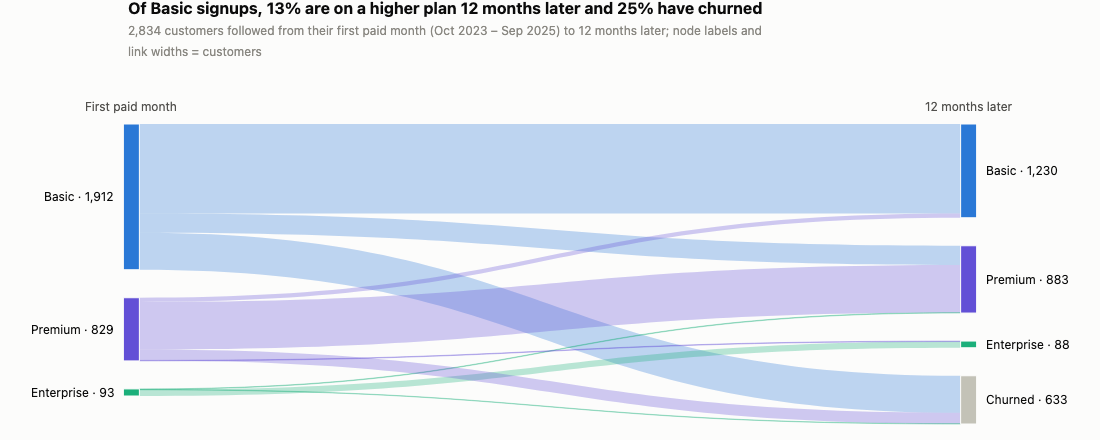

In [3]:
show(T.fig_sankey(12))

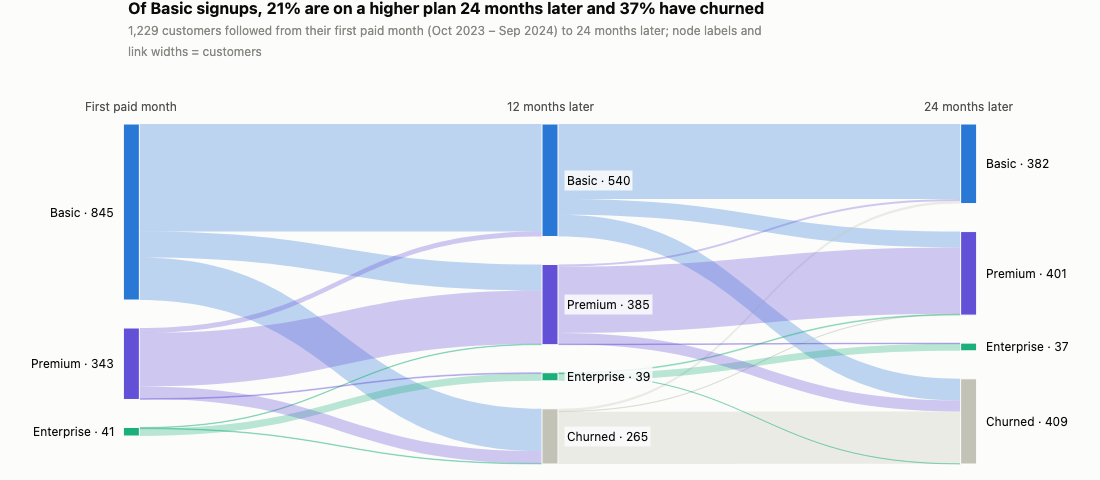

In [4]:
show(T.fig_sankey(24))

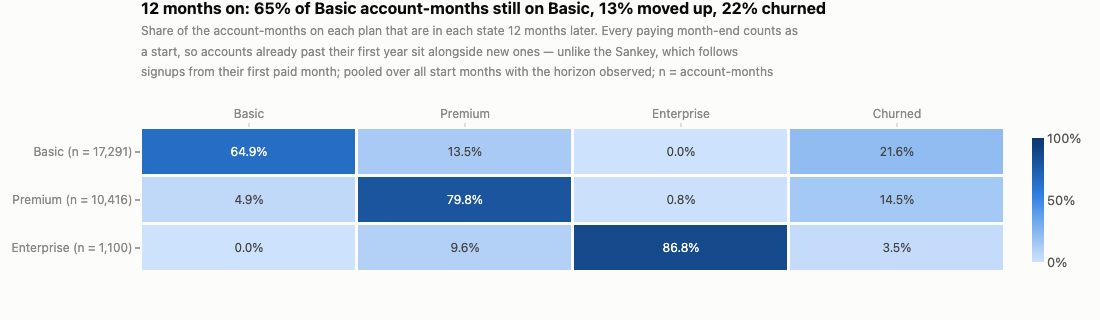

In [5]:
show(T.fig_transition_heatmap(12))

In [6]:
tm = marts.load('transitions__transition_matrix')
tm.pivot_table(index=['from_plan', 'horizon_months'], columns='to_state', values='share_of_from_plan', fill_value=0)[T.STATES]

to_state                   basic  premium  enterprise  churned
from_plan  horizon_months                                     
basic      3              0.8955   0.0388      0.0000   0.0656
           6              0.8053   0.0754      0.0000   0.1193
           12             0.6488   0.1349      0.0000   0.2163
           24             0.4540   0.2101      0.0000   0.3359
enterprise 3              0.0000   0.0145      0.9799   0.0056
           6              0.0000   0.0338      0.9542   0.0120
           12             0.0000   0.0964      0.8682   0.0355
           24             0.0264   0.1283      0.8113   0.0340
premium    3              0.0157   0.9426      0.0017   0.0401
           6              0.0285   0.8919      0.0036   0.0759
           12             0.0493   0.7980      0.0082   0.1446
           24             0.0634   0.6786      0.0147   0.2433

In [7]:
t24 = k['transition_24m_basic']
md(f"""**Reading.** Most Basic signups stay on Basic: of the {k['signups_observed_12m']:,} customers with 12 months of history, those who started on Basic are {pct(s12.get('basic', 0), 0)} still on Basic 12 months later, {pct(s12.get('premium', 0) + s12.get('enterprise', 0), 0)} on a higher plan and {pct(s12.get('churned', 0), 0)} churned (Sankey); at 24 months ({k['signups_observed_24m']:,} customers) {pct(s24.get('premium', 0) + s24.get('enterprise', 0), 0)} have moved up and {pct(s24.get('churned', 0), 0)} churned.
The transition matrix gives {pct(t12['basic'], 0)} / {pct(t12['premium'] + t12['enterprise'], 0)} / {pct(t12['churned'], 0)} at 12 months ({pct(t24['premium'] + t24['enterprise'], 0)} moved up and {pct(t24['churned'], 0)} churned at 24): it counts every paying Basic month-end as a start, so accounts already past their first year — which churn less — are in it too, and its churn share is lower than the signups'.
Premium → Basic is rare ({pct(t12p['basic'], 1)} of Premium account-months in 12 months) and Premium → Enterprise rarer still ({pct(t12p['enterprise'], 1)}).""")

**Reading.** Most Basic signups stay on Basic: of the 2,834 customers with 12 months of history, those who started on Basic are 61% still on Basic 12 months later, 13% on a higher plan and 25% churned (Sankey); at 24 months (1,229 customers) 21% have moved up and 37% churned.
The transition matrix gives 65% / 13% / 22% at 12 months (21% moved up and 34% churned at 24): it counts every paying Basic month-end as a start, so accounts already past their first year — which churn less — are in it too, and its churn share is lower than the signups'.
Premium → Basic is rare (4.9% of Premium account-months in 12 months) and Premium → Enterprise rarer still (0.8%).

### 2. Who upgrades from Basic

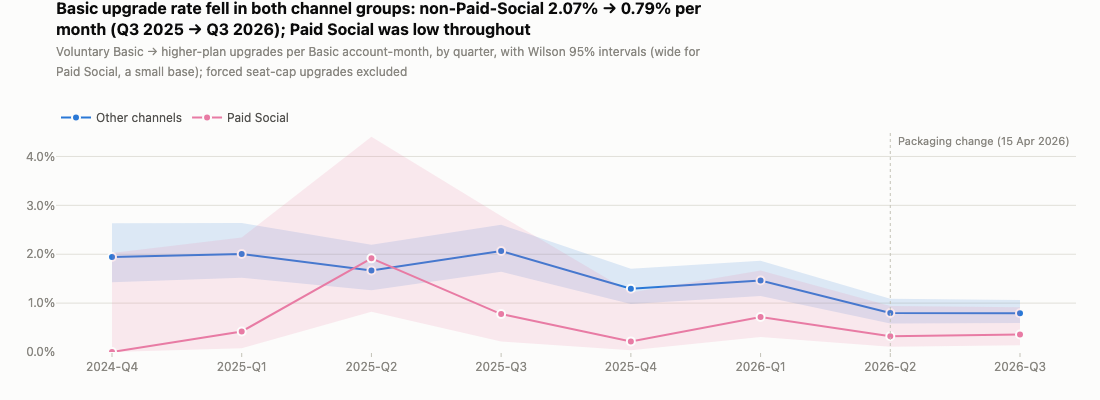

In [8]:
show(T.fig_upgrade_rate_quarterly())

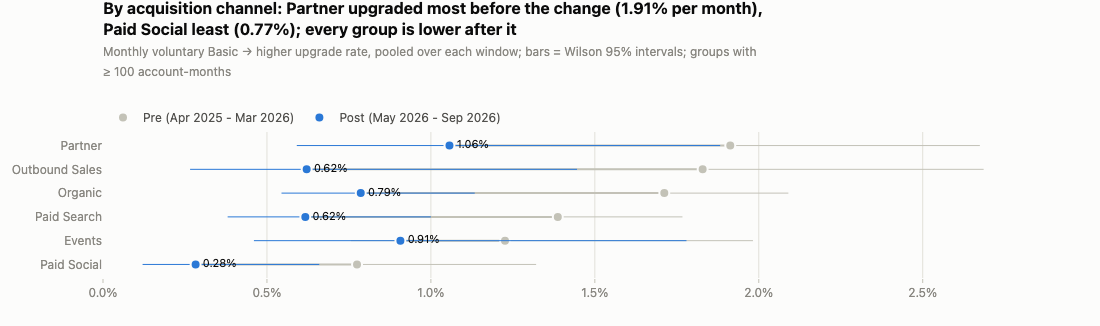

In [9]:
show(T.fig_upgrade_rate_pre_post('acquisition_channel'))

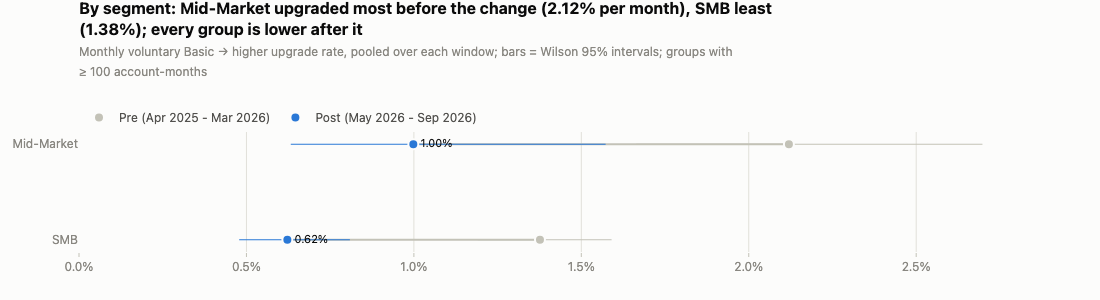

In [10]:
show(T.fig_upgrade_rate_pre_post('segment'))

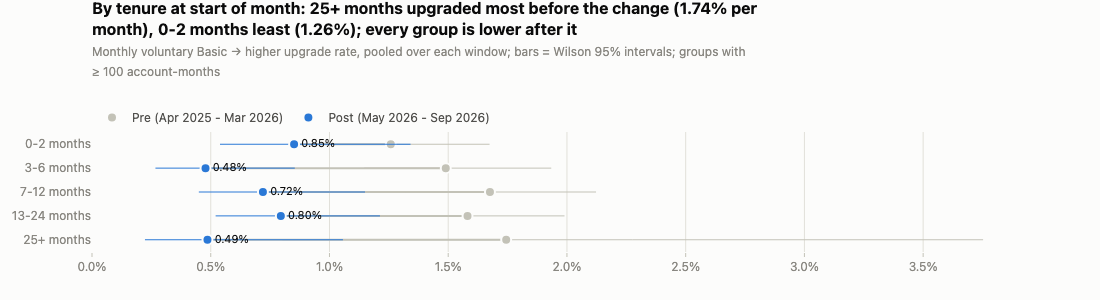

In [11]:
show(T.fig_upgrade_rate_pre_post('tenure_band'))

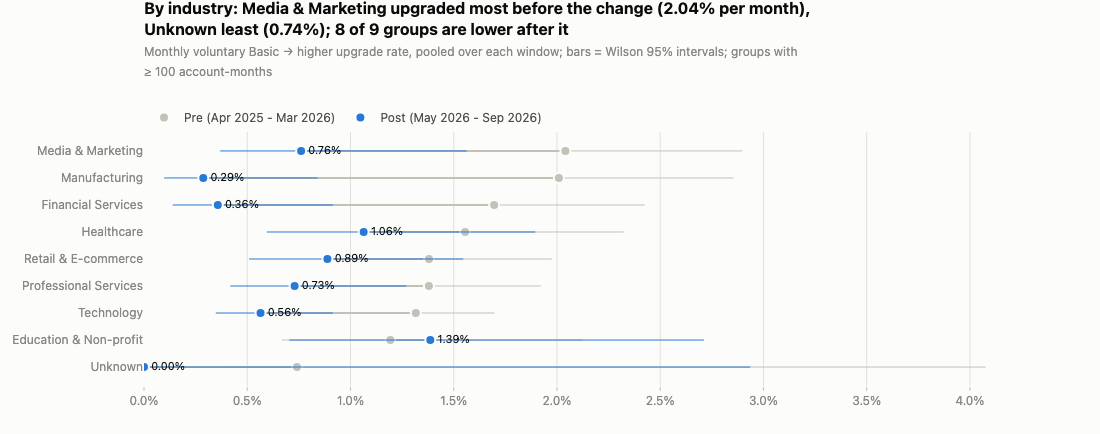

In [12]:
show(T.fig_upgrade_rate_pre_post('industry'))

In [13]:
pp = marts.load('transitions__upgrade_rate_pre_post')
pp[['dimension', 'group', 'n_pre', 'upgrades_pre', 'forced_pre', 'rate_pre', 'n_post', 'upgrades_post', 'forced_post', 'rate_post',
    'change_pts', 'change_lo', 'change_hi', 'rel_change']]

,dimension,group,n_pre,upgrades_pre,forced_pre,rate_pre,n_post,upgrades_post,forced_post,rate_post,change_pts,change_lo,change_hi,rel_change
0,segment,Mid-Market,3019,64,4,0.0212,1803,18,1,0.0100,-0.0112,-0.0181,-0.0039,-0.5291
1,segment,SMB,13149,181,2,0.0138,8840,55,2,0.0062,-0.0075,-0.0101,-0.0049,-0.5480
2,acquisition_channel,Events,1305,16,0,0.0123,882,8,1,0.0091,-0.0032,-0.0120,0.0067,-0.2602
3,acquisition_channel,Organic,5491,94,1,0.0171,3562,28,0,0.0079,-0.0093,-0.0137,-0.0046,-0.5408
4,acquisition_channel,Outbound Sales,1367,25,0,0.0183,805,5,0,0.0062,-0.0121,-0.0214,-0.0020,-0.6604
5,acquisition_channel,Paid Search,4614,64,1,0.0139,2593,16,1,0.0062,-0.0077,-0.0122,-0.0028,-0.5551
6,acquisition_channel,Paid Social,1678,13,1,0.0077,1770,5,0,0.0028,-0.0049,-0.0106,0.0000,-0.6354
7,acquisition_channel,Partner,1725,33,3,0.0191,1041,11,1,0.0106,-0.0086,-0.0175,0.0013,-0.4476
8,industry,Education & Non-profit,922,11,0,0.0119,577,8,0,0.0139,0.0019,-0.0096,0.0162,0.1621
9,industry,Financial Services,1710,29,1,0.0170,1119,4,0,0.0036,-0.0134,-0.0210,-0.0058,-0.7892


In [14]:
seg = pp[pp.dimension == 'segment'].set_index('group')
bil = pp[pp.dimension == 'billing_period'].set_index('group')
ten = pp[pp.dimension == 'tenure_band'].set_index('group')
chn = pp[pp.dimension == 'acquisition_channel'].set_index('group').sort_values('rate_pre', ascending=False)
ind = pp[pp.dimension == 'industry'].set_index('group')
first_year = [ten.loc[b, 'rate_pre'] for b in ('0-2 months', '3-6 months', '7-12 months')]
rises = all(a < b for a, b in zip(first_year, first_year[1:]))
bil_overlap = bil.loc['annual', 'lo_pre'] <= bil.loc['monthly', 'hi_pre'] and bil.loc['monthly', 'lo_pre'] <= bil.loc['annual', 'hi_pre']
lower = {d: (int((pp[pp.dimension == d].change_pts < 0).sum()), int((pp.dimension == d).sum())) for d in pp.dimension.unique()}
ind_up = [f"{g}, {pts(r.change_pts, 2)} (95%: {pts(r.change_lo, 2)} to {pts(r.change_hi, 2)})" for g, r in ind[ind.change_pts >= 0].iterrows()]
first_month = T._basic_base()['month_end'].min()
md(f"""**Reading.** Before the change, the sales-touched channels upgraded most ({chn.index[0]} {pct(chn.rate_pre.iloc[0], 2)}, {chn.index[1]} {pct(chn.rate_pre.iloc[1], 2)} per month) and Paid Social least ({pct(k['upgrade_rate_ps_pre'], 2)}); Mid-Market Basic accounts upgraded at {pct(seg.loc['Mid-Market', 'rate_pre'], 2)} vs {pct(seg.loc['SMB', 'rate_pre'], 2)} for SMB,
and annual vs monthly billing made {'little' if bil_overlap else 'a clear'} difference ({pct(bil.loc['annual', 'rate_pre'], 2)} vs {pct(bil.loc['monthly', 'rate_pre'], 2)}). Upgrade propensity {'rises' if rises else 'does not rise steadily'} with tenure through the first year ({pct(first_year[0], 2)} at 0–2 months, {pct(first_year[1], 2)} at 3–6, {pct(first_year[2], 2)} at 7–12).
After the change the rate is lower in {lower['acquisition_channel'][0]} of {lower['acquisition_channel'][1]} channels, {lower['segment'][0]} of {lower['segment'][1]} segments, {lower['tenure_band'][0]} of {lower['tenure_band'][1]} tenure bands, {lower['billing_period'][0]} of {lower['billing_period'][1]} billing periods and {lower['industry'][0]} of {lower['industry'][1]} industries{' (the exception: ' + '; '.join(ind_up) + ')' if ind_up else ''} — the pattern of a product-wide change, not of one customer group.
Forced seat-cap upgrades are rare ({k['forced_upgrades_total']} since {first_month:%b %Y}) and do not change any of this.""")

**Reading.** Before the change, the sales-touched channels upgraded most (Partner 1.91%, Outbound Sales 1.83% per month) and Paid Social least (0.77%); Mid-Market Basic accounts upgraded at 2.12% vs 1.38% for SMB,
and annual vs monthly billing made little difference (1.59% vs 1.47%). Upgrade propensity rises with tenure through the first year (1.26% at 0–2 months, 1.49% at 3–6, 1.68% at 7–12).
After the change the rate is lower in 6 of 6 channels, 2 of 2 segments, 5 of 5 tenure bands, 2 of 2 billing periods and 8 of 9 industries (the exception: Education & Non-profit, +0.19 pts (95%: −0.96 pts to +1.62 pts)) — the pattern of a product-wide change, not of one customer group.
Forced seat-cap upgrades are rare (10 since Nov 2023) and do not change any of this.

### 3. Why upgrades fell: channel mix vs within-channel rates, and timing

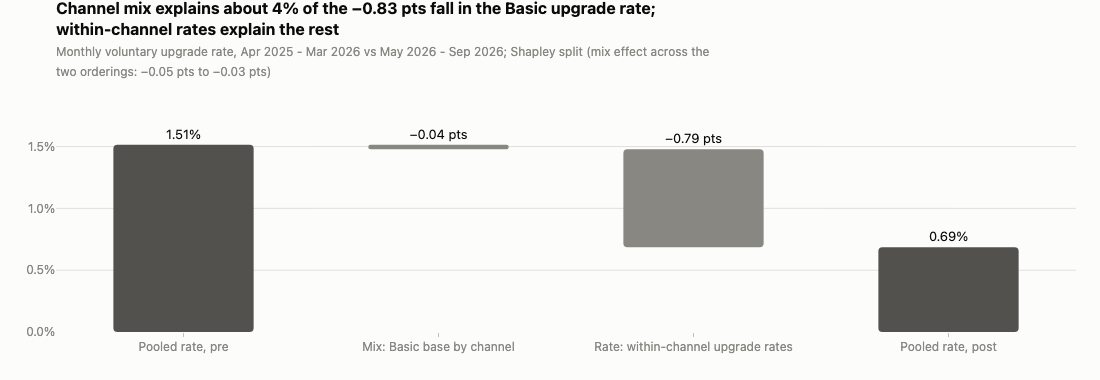

In [15]:
summary, table = T.mix_rate_decomposition()
show(T.fig_mix_rate(summary))

In [16]:
table[['cell', 'n_pre', 'up_pre', 'w_pre', 'r_pre', 'n_post', 'up_post', 'w_post', 'r_post', 'mix_at_pre_rates', 'rate_at_post_mix',
       'mix_at_post_rates', 'rate_at_pre_mix', 'mix_shapley', 'rate_shapley']]

,cell,n_pre,up_pre,w_pre,r_pre,n_post,up_post,w_post,r_post,mix_at_pre_rates,rate_at_post_mix,mix_at_post_rates,rate_at_pre_mix,mix_shapley,rate_shapley
0,Events,1305,16,0.0807,0.0123,882,8,0.0828,0.0091,0.0000,-0.0003,0.0000,-0.0003,0.0000,-0.0003
1,Organic,5491,94,0.3394,0.0171,3562,28,0.3344,0.0079,-0.0001,-0.0031,-0.0000,-0.0031,-0.0001,-0.0031
2,Outbound Sales,1367,25,0.0845,0.0183,805,5,0.0756,0.0062,-0.0002,-0.0009,-0.0001,-0.0010,-0.0001,-0.0010
3,Paid Search,4614,64,0.2852,0.0139,2593,16,0.2434,0.0062,-0.0006,-0.0019,-0.0003,-0.0022,-0.0004,-0.0020
4,Paid Social,1678,13,0.1037,0.0077,1770,5,0.1662,0.0028,0.0005,-0.0008,0.0002,-0.0005,0.0003,-0.0007
5,Partner,1725,33,0.1066,0.0191,1041,11,0.0977,0.0106,-0.0002,-0.0008,-0.0001,-0.0009,-0.0001,-0.0009


In [17]:
summary_ct, table_ct = T.mix_rate_decomposition(by='channel_tech')
table_ct[['cell', 'n_pre', 'up_pre', 'w_pre', 'r_pre', 'n_post', 'up_post', 'w_post', 'r_post', 'mix_shapley', 'rate_shapley']]

,cell,n_pre,up_pre,w_pre,r_pre,n_post,up_post,w_post,r_post,mix_shapley,rate_shapley
0,Other channels / Non-Technology,10617,178,0.6562,0.0168,6514,54,0.6115,0.0083,-0.0006,-0.0054
1,Other channels / Technology,3885,54,0.2401,0.0139,2369,14,0.2224,0.0059,-0.0002,-0.0018
2,Paid Social / Non-Technology,1157,9,0.0715,0.0078,1304,3,0.1224,0.0023,0.0003,-0.0005
3,Paid Social / Technology,521,4,0.0322,0.0077,466,2,0.0437,0.0043,0.0001,-0.0001


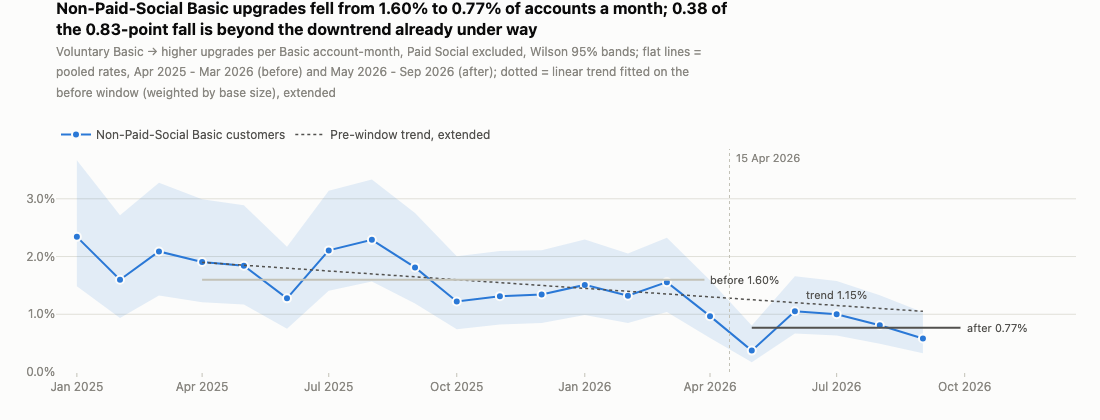

In [18]:
show(T.fig_upgrade_rate_monthly())

In [19]:
# the drift inside the pre window, by segment: first half vs second half of the pre window (both before April 2026)
dseg = T.drift_check(dim='segment')
dseg

,dimension,group,n_early,n_late,upgrades_early,upgrades_late,rate_early,rate_late,early_window,late_window
1,segment,Mid-Market,1232,1620,31,30,0.0252,0.0185,Apr 2025 - Sep 2025,Oct 2025 - Mar 2026
2,segment,SMB,5090,6548,88,83,0.0173,0.0127,Apr 2025 - Sep 2025,Oct 2025 - Mar 2026


In [20]:
sd = T.step_vs_drift()
qo = T.upgrade_rate_quarterly('channel_group')
qo = qo[qo.group == T.GROUP_OTHER].set_index('quarter_label')['rate']
mid_q, late_q = qo[['2025-Q2', '2025-Q3']], qo[['2025-Q4', '2026-Q1']]
dsg = dseg.set_index('group')
within_all = bool((dsg.rate_late < dsg.rate_early).all())
seg_txt = ', '.join(f"{g} {pct(r.rate_early, 2)} → {pct(r.rate_late, 2)}" for g, r in dsg.iterrows())
low = pd.Timestamp(k['non_ps_lowest_month'])
low_txt = f"The lowest month is {low:%B %Y}" + (", the first full month after the change." if low == pd.Timestamp('2026-05-31') else ".")
raw, step = sd['raw_change_pts'], sd['step_net_of_trend_pts']
trig = k['product_trigger_threshold_rel']
both_past = k['upgrade_rate_controlled_rel_change'] <= trig and sd['step_net_of_trend_rel'] <= trig
half_txt = ', so even the low end is under half of that raw fall' if abs(step) < abs(raw) / 2 else ''
md(f"""**Reading.**
- *Mix.* The Basic base shifted toward Paid Social ({pct(summary['paid_social_share_pre'], 1)} → {pct(summary['paid_social_share_post'], 1)} of account-months), a channel whose monthly upgrade rate was {pct(k['upgrade_rate_ps_pre'], 2)} against {pct(k['upgrade_rate_non_ps_pre'], 2)} for the others before the change. That explains {pts(summary['mix_shapley'], 2)} of the {pts(summary['change_pts'], 2)} fall — {pct(summary['mix_share_of_change'], 0)}; the two orderings give {pts(summary['mix_at_post_rates'], 2)} and {pts(summary['mix_at_pre_rates'], 2)}, so the overlap is immaterial. Adding Technology as a second mix dimension changes little ({pts(summary_ct['mix_shapley'], 2)}).
- *Rate.* Within-channel rates explain {pts(summary['rate_shapley'], 2)}. Non-Paid-Social: {pct(k['upgrade_rate_non_ps_pre'], 2)} → {pct(k['upgrade_rate_non_ps_post'], 2)}; non-Paid-Social, non-Technology: {pct(k['upgrade_rate_controlled_pre'], 2)} → {pct(k['upgrade_rate_controlled_post'], 2)} ({pct(k['upgrade_rate_controlled_rel_change'], 0)}, 95%: {pts(k['upgrade_rate_controlled_change_lo'], 2)} to {pts(k['upgrade_rate_controlled_change_hi'], 2)}).
- *Timing.* The non-Paid-Social rate was not flat before April: it ran at {pct(mid_q.min(), 1)}–{pct(mid_q.max(), 1)} a month in Q2–Q3 2025 and {pct(late_q.min(), 1)}–{pct(late_q.max(), 1)} in Q4 2025 – Q1 2026 (slope {pts(sd['slope_pts_per_month'], 3)} per month over the pre window). {'The drift shows up within both segments (' + seg_txt + ', ' + dseg.early_window.iloc[0] + ' vs ' + dseg.late_window.iloc[0] + '), so it is not a shift in segment mix; the billing data does not say what drove it.' if within_all else 'The drift is not visible in every segment (' + seg_txt + '); the billing data does not say what drove it.'} Extending the trend gives {pct(sd['extrapolated_post'], 2)} for May – Sep 2026 against an actual {pct(sd['actual_post'], 2)}: {abs(step) * 100:.2f} of the {abs(raw) * 100:.2f}-point fall ({pct(sd['step_net_of_trend_rel'], 0)} against the trend) is beyond it, versus {pts(raw, 2)} against the pre-window mean. The three months before April vs the three after: {pct(sd['rate_jan_mar_2026'], 2)} → {pct(sd['rate_may_jul_2026'], 2)} ({pts(sd['step_3m_pts'], 2)}, 95%: {pts(sd['step_3m_lo'], 2)} to {pts(sd['step_3m_hi'], 2)}). {low_txt}
- *So:* the fall lines up in time with the packaging change, but part of it was under way before. The part that coincides with the change is {abs(step) * 100:.1f} to {abs(sd['step_from_pre_april_level_pts']) * 100:.1f} points a month ({abs(step) * 100:.1f} if the earlier drift had continued, {abs(sd['step_from_pre_april_level_pts']) * 100:.1f} if the rate had held at its pre-April level) — a range, not a measured effect; the {abs(raw) * 100:.2f}-point fall against the pre-window average includes the drift{half_txt}. {'Under the Product trigger (' + pct(k['product_trigger_threshold_rel'], 0) + ' controlled for Paid Social and Technology) every reading qualifies.' if both_past else 'Not every reading clears the Product trigger (' + pct(k['product_trigger_threshold_rel'], 0) + ').'} This is a before / after comparison on observational data; a holdout is the only clean test.""")

**Reading.**
- *Mix.* The Basic base shifted toward Paid Social (10.4% → 16.6% of account-months), a channel whose monthly upgrade rate was 0.77% against 1.60% for the others before the change. That explains −0.04 pts of the −0.83 pts fall — 4%; the two orderings give −0.03 pts and −0.05 pts, so the overlap is immaterial. Adding Technology as a second mix dimension changes little (−0.04 pts).
- *Rate.* Within-channel rates explain −0.79 pts. Non-Paid-Social: 1.60% → 0.77%; non-Paid-Social, non-Technology: 1.68% → 0.83% (−51%, 95%: −1.17 pts to −0.51 pts).
- *Timing.* The non-Paid-Social rate was not flat before April: it ran at 1.7%–2.1% a month in Q2–Q3 2025 and 1.3%–1.5% in Q4 2025 – Q1 2026 (slope −0.050 pts per month over the pre window). The drift shows up within both segments (Mid-Market 2.52% → 1.85%, SMB 1.73% → 1.27%, Apr 2025 - Sep 2025 vs Oct 2025 - Mar 2026), so it is not a shift in segment mix; the billing data does not say what drove it. Extending the trend gives 1.15% for May – Sep 2026 against an actual 0.77%: 0.38 of the 0.83-point fall (−33% against the trend) is beyond it, versus −0.83 pts against the pre-window mean. The three months before April vs the three after: 1.46% → 0.82% (−0.64 pts, 95%: −1.10 pts to −0.22 pts). The lowest month is May 2026, the first full month after the change.
- *So:* the fall lines up in time with the packaging change, but part of it was under way before. The part that coincides with the change is 0.4 to 0.6 points a month (0.4 if the earlier drift had continued, 0.6 if the rate had held at its pre-April level) — a range, not a measured effect; the 0.83-point fall against the pre-window average includes the drift, so even the low end is under half of that raw fall. Under the Product trigger (−20% controlled for Paid Social and Technology) every reading qualifies. This is a before / after comparison on observational data; a holdout is the only clean test.

### 4. The packaging change's upside: Basic retention, and the net effect

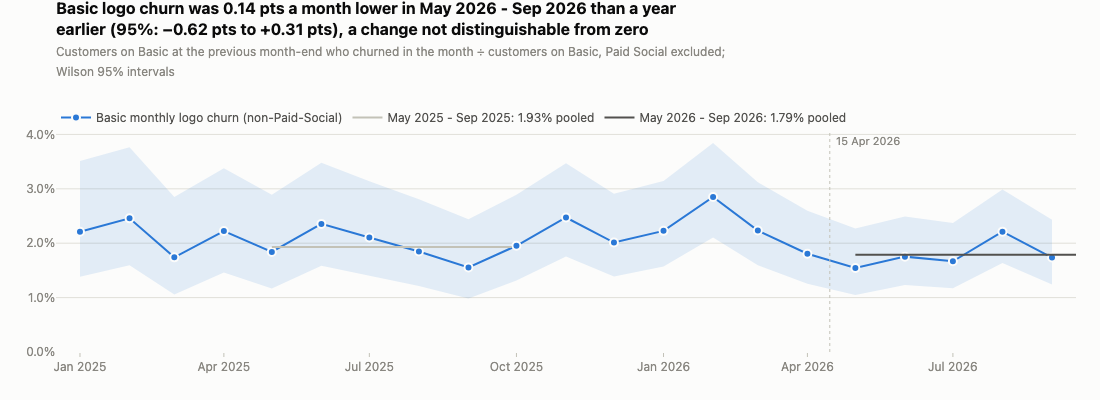

In [21]:
show(T.fig_basic_churn_monthly())

In [22]:
ch = T.basic_churn_compare()
ch_nt = T.basic_churn_compare(exclude_technology=True)
ch_all = T.basic_churn_compare(exclude_paid_social=False)
pd.DataFrame([ch, ch_nt, ch_all])[['window_a', 'window_b', 'exclude_paid_social', 'exclude_technology', 'n_a', 'churn_a', 'n_b', 'churn_b',
                                   'change_pts', 'change_lo', 'change_hi', 'rel_change']]

,window_a,window_b,exclude_paid_social,exclude_technology,n_a,churn_a,n_b,churn_b,change_pts,change_lo,change_hi,rel_change
0,May 2025 - Sep 2025,May 2026 - Sep 2026,True,False,5384,0.0193,8883,0.0179,-0.0014,-0.0062,0.0031,-0.0734
1,May 2025 - Sep 2025,May 2026 - Sep 2026,True,True,3970,0.0191,6514,0.0166,-0.0026,-0.0081,0.0025,-0.1339
2,May 2025 - Sep 2025,May 2026 - Sep 2026,False,False,5818,0.0222,10653,0.0225,0.0004,-0.0045,0.0049,0.0161


In [23]:
net = T.net_mrr_effect()
pd.Series(net).to_frame('value')

,value
basic_base_non_ps_per_month,"1,776.6000"
mrr_per_upgrade,206.1562
mrr_per_basic_account,141.4502
upgrade_rate_change_pts,-0.0083
upgrade_rate_step_net_of_trend_pts,-0.0038
churn_change_pts,-0.0014
foregone_upgrade_mrr_per_month,"-3,055.5819"
foregone_upgrade_mrr_lo,"-4,046.7614"
foregone_upgrade_mrr_hi,"-2,030.8413"
foregone_upgrade_mrr_trend_adjusted,"-1,398.5389"


In [24]:
sig = marts.load('transitions__signup_states')
nb_ = sig[(sig.plan_0 == 'basic') & (sig.acquisition_channel != 'Paid Social')].groupby('cohort_month_end').size()
def yoy(lo, hi):
    lo, hi = pd.Timestamp(lo), pd.Timestamp(hi)
    cur = nb_[(nb_.index >= lo) & (nb_.index <= hi)].sum()
    prev = nb_[(nb_.index >= lo - pd.offsets.MonthEnd(12)) & (nb_.index <= hi - pd.offsets.MonthEnd(12))].sum()
    return cur / prev - 1
g_post, g_pre = yoy('2026-05-31', '2026-09-30'), yoy('2025-10-31', '2026-03-31')
md(f"""**Reading.** Basic logo churn among non-Paid-Social accounts is {pct(ch['churn_a'], 2)} → {pct(ch['churn_b'], 2)} per month, {pts(ch['change_pts'], 2)} ({pct(ch['rel_change'], 0)}), with a 95% interval of {pts(ch['change_lo'], 2)} to {pts(ch['change_hi'], 2)}
— the direction Product hoped for, but five months of data cannot distinguish it from zero (excluding Technology: {pts(ch_nt['change_pts'], 2)}, {pts(ch_nt['change_lo'], 2)} to {pts(ch_nt['change_hi'], 2)}).
If the before / after differences are put down to the packaging change, then on the non-Paid-Social Basic base of about {net['basic_base_non_ps_per_month']:,.0f} accounts the lower upgrade rate costs {money(net['foregone_upgrade_mrr_per_month'])} of new MRR per month
({money(net['foregone_upgrade_mrr_lo'])} to {money(net['foregone_upgrade_mrr_hi'])}; {money(net['foregone_upgrade_mrr_trend_adjusted'])} if the pre-window drift is assumed to have continued) at {money(net['mrr_per_upgrade'])} per upgrade,
while the churn change keeps {money(net['retained_basic_mrr_per_month'])} per month ({money(net['retained_basic_mrr_lo'])} to {money(net['retained_basic_mrr_hi'])}) at {money(net['mrr_per_basic_account'])} per account.
**Net: {money(net['net_mrr_per_month'])} per month** (range {money(net['net_mrr_lo'])} to {money(net['net_mrr_hi'])}; {money(net['net_mrr_per_month_trend_adjusted'])} trend-adjusted), which compounds to about {money(net['net_mrr_12m_run_rate'])} of run-rate after 12 months
({money(net['net_mrr_12m_run_rate_trend_adjusted'])} trend-adjusted) against {money(k['basic_mrr_sep_2026'])} of Basic MRR. Trial → paid conversion is outside the billing data (scope §5), so the upside is understated if conversion improved: new Basic signups outside Paid Social were {pct(g_post, 0, signed=True)} year on year in May – Sep 2026, but already {pct(g_pre, 0, signed=True)} in the six months before the change, so the billing data cannot separate a conversion lift from acquisition growth.""")

**Reading.** Basic logo churn among non-Paid-Social accounts is 1.93% → 1.79% per month, −0.14 pts (−7%), with a 95% interval of −0.62 pts to +0.31 pts
— the direction Product hoped for, but five months of data cannot distinguish it from zero (excluding Technology: −0.26 pts, −0.81 pts to +0.25 pts).
If the before / after differences are put down to the packaging change, then on the non-Paid-Social Basic base of about 1,777 accounts the lower upgrade rate costs −$3.1K of new MRR per month
(−$4.0K to −$2.0K; −$1.4K if the pre-window drift is assumed to have continued) at $206 per upgrade,
while the churn change keeps $356 per month (−$769 to $1.6K) at $141 per account.
**Net: −$2.7K per month** (range −$4.8K to −$475; −$1.0K trend-adjusted), which compounds to about −$32.4K of run-rate after 12 months
(−$12.5K trend-adjusted) against $317K of Basic MRR. Trial → paid conversion is outside the billing data (scope §5), so the upside is understated if conversion improved: new Basic signups outside Paid Social were +34% year on year in May – Sep 2026, but already +25% in the six months before the change, so the billing data cannot separate a conversion lift from acquisition growth.

### 5. Downgrades: who, who initiated them, and what happens after a CS save

In [25]:
ds = marts.load('transitions__downgrade_summary_12m')
ds[['flow', 'source_label', 'downgrades', 'customers', 'mrr_before', 'mrr_delta', 'mrr_retained_share', 'seats_cut_share', 'observed_6m', 'paying_6m_share']]

,flow,source_label,downgrades,customers,mrr_before,mrr_delta,mrr_retained_share,seats_cut_share,observed_6m,paying_6m_share
0,Premium → Basic,CS save,33,33,"19,258.6800","-12,001.6800",0.3768,0.3939,17,0.8235
1,Premium → Basic,At renewal,10,10,"3,871.0000","-2,179.0000",0.4371,0.0000,6,1.0000
2,Premium → Basic,Self-serve,32,32,"14,595.0000","-8,370.0000",0.4265,0.0625,14,0.9286
3,Enterprise → Premium,CS save,1,1,"7,955.0000","-4,483.0000",0.4365,1.0000,0,NaN
4,Enterprise → Premium,At renewal,6,6,"14,857.5000","-6,709.5000",0.5484,0.6667,5,1.0000


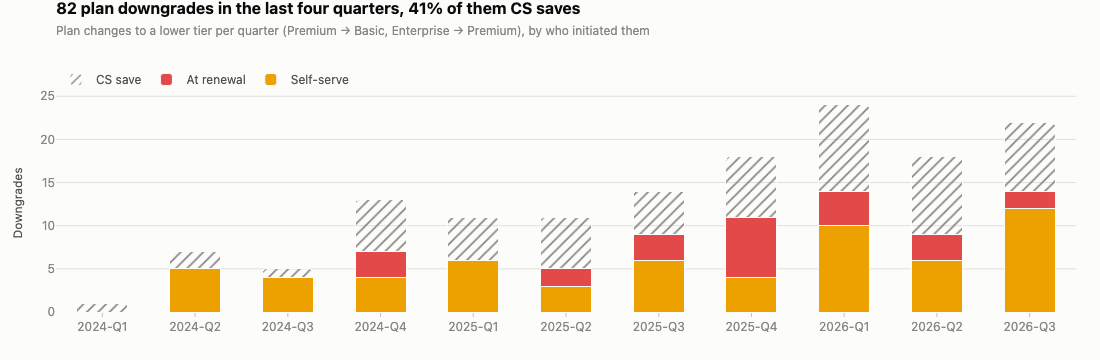

In [26]:
show(T.fig_downgrades_quarterly())

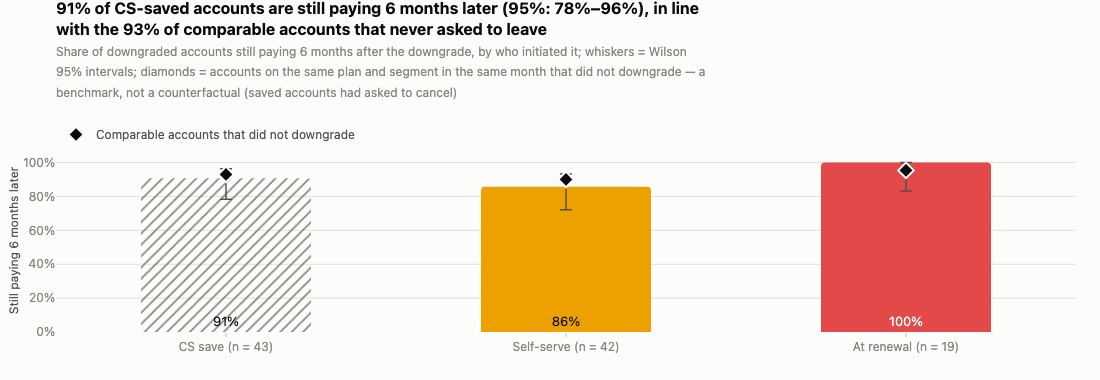

In [27]:
show(T.fig_downgrade_survival(6))

In [28]:
sv = marts.load('transitions__downgrade_survival')
sv[['horizon_months', 'source_label', 'downgrades', 'paying', 'paying_share', 'lo', 'hi', 'comparable_paying', 'gap_vs_comparable_pts', 'mrr_retained_share']]

,horizon_months,source_label,downgrades,paying,paying_share,lo,hi,comparable_paying,gap_vs_comparable_pts,mrr_retained_share
0,6,CS save,43,39.0000,0.9070,0.7840,0.9632,0.9297,-0.0227,0.4122
1,6,Self-serve,42,36.0000,0.8571,0.7216,0.9328,0.9003,-0.0431,0.4234
2,6,At renewal,19,19.0000,1.0000,0.8318,1.0000,0.9538,0.0462,0.5077
3,12,Self-serve,28,21.0000,0.7500,0.5664,0.8732,0.7968,-0.0468,0.4238
4,12,CS save,26,21.0000,0.8077,0.6212,0.9149,0.8781,-0.0705,0.4111
5,12,At renewal,8,7.0000,0.8750,0.5291,0.9776,0.8901,-0.0151,0.5257


In [29]:
dg = marts.load('transitions__downgrades')
dg[dg.month_end >= '2025-10-31'].groupby(['source_label', 'segment']).size().unstack(fill_value=0)

segment,Enterprise,Mid-Market,SMB
source_label,,,
At renewal,4,6,6
CS save,1,18,15
Self-serve,1,11,20


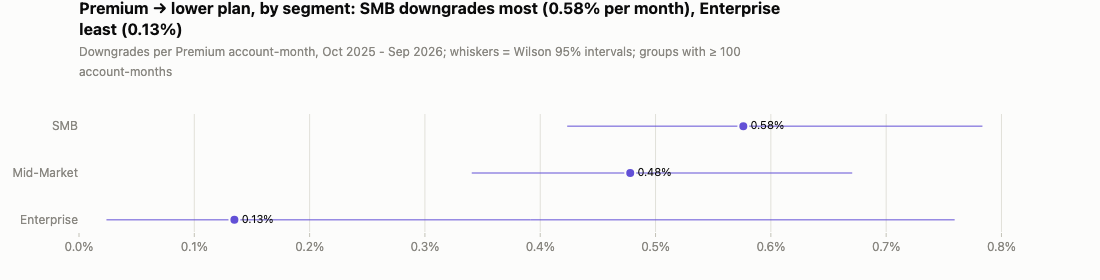

In [30]:
show(T.fig_downgrade_rate('segment'))

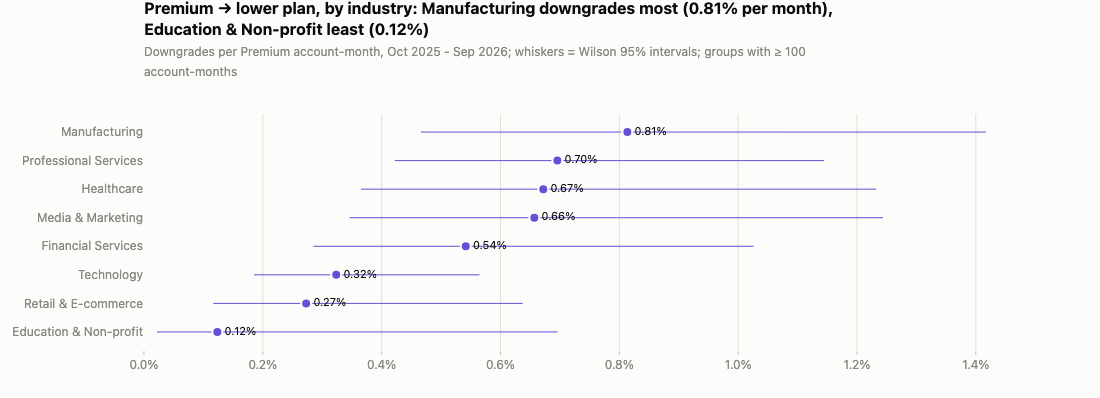

In [31]:
show(T.fig_downgrade_rate('industry'))

In [32]:
dr = marts.load('transitions__downgrade_rate_12m')
dr[['dimension', 'group', 'n', 'downgrades', 'rate', 'lo', 'hi']]

,dimension,group,n,downgrades,rate,lo,hi
0,segment,SMB,6943,40,0.0058,0.0042,0.0078
1,segment,Mid-Market,6903,33,0.0048,0.0034,0.0067
2,segment,Enterprise,742,1,0.0013,0.0002,0.0076
3,acquisition_channel,Paid Social,890,13,0.0146,0.0086,0.0248
4,acquisition_channel,Events,1307,8,0.0061,0.0031,0.0120
5,acquisition_channel,Organic,4420,23,0.0052,0.0035,0.0078
6,acquisition_channel,Paid Search,3209,16,0.0050,0.0031,0.0081
7,acquisition_channel,Partner,2357,9,0.0038,0.0020,0.0072
8,acquisition_channel,Outbound Sales,2405,5,0.0021,0.0009,0.0049
9,industry,Manufacturing,1475,12,0.0081,0.0047,0.0142


In [33]:
sv6 = sv[sv.horizon_months == 6].set_index('change_source')
sv12 = sv[sv.horizon_months == 12].set_index('change_source')
drs = dr[dr.dimension == 'segment'].set_index('group')
dri = dr[dr.dimension == 'industry'].sort_values('rate')
overlap = dri.iloc[0]['hi'] >= dri.iloc[-1]['lo']
gap6, gap12 = (s.loc['customer_success', 'paying_share'] - s.loc['customer_success', 'comparable_paying'] for s in (sv6, sv12))
md(f"""**Reading.** Downgrades are few: {k['downgrades_last_12m']} in the last 12 months against {k['downgrades_prior_12m']} in the 12 before, while the rate per Premium / Enterprise account-month went {pct(k['downgrade_rate_prior_12m'], 2)} → {pct(k['downgrade_rate_last_12m'], 2)} — {'the count rose because the base grew, not the rate' if k['downgrade_rate_last_12m'] <= k['downgrade_rate_prior_12m'] else 'the rate rose as well as the base'}. {k['downgrades_last_12m_premium_to_basic']} of them were Premium → Basic. By who initiated them: {d12.get('customer_success', 0)} CS saves (the account asked to cancel and was kept on a smaller plan), {d12.get('self_serve', 0)} self-serve in the billing portal, {d12.get('renewal', 0)} at an annual renewal.
A downgrade keeps {pct(k['downgrades_last_12m_mrr_retained_share'], 0)} of the account's MRR on average, and {pct(k['downgrades_last_12m_seats_cut_share'], 0)} also cut seats.
Per Premium account-month the downgrade rate is {pct(drs.loc['SMB', 'rate'], 2)} for SMB vs {pct(drs.loc['Mid-Market', 'rate'], 2)} for Mid-Market; by industry it runs from {pct(dri.iloc[0]['rate'], 2)} ({dri.iloc[0]['group']}) to {pct(dri.iloc[-1]['rate'], 2)} ({dri.iloc[-1]['group']}), {'with intervals that overlap — with this few events, industry is not a reliable predictor' if overlap else 'and the two intervals do not overlap'}.
Six months later {pct(sv6.loc['customer_success', 'paying_share'], 0)} of CS-saved accounts are still paying (95%: {pct(sv6.loc['customer_success', 'lo'], 0)}–{pct(sv6.loc['customer_success', 'hi'], 0)}), against {pct(sv6.loc['customer_success', 'comparable_paying'], 0)} of comparable accounts that never asked to leave and {pct(sv6.loc['self_serve', 'paying_share'], 0)} of self-serve downgrades.
With {int(sv6.loc['customer_success', 'downgrades'])} observed saves the interval is wide, but the point estimate says the save holds at six months: these accounts stay, at {pct(sv6.loc['customer_success', 'mrr_retained_share'], 0)} of their former MRR. The 12-month read is thinner{' and weaker' if gap12 < gap6 else ''} — {pct(sv12.loc['customer_success', 'paying_share'], 0)} still paying (95%: {pct(sv12.loc['customer_success', 'lo'], 0)}–{pct(sv12.loc['customer_success', 'hi'], 0)}, n = {int(sv12.loc['customer_success', 'downgrades'])}) vs {pct(sv12.loc['customer_success', 'comparable_paying'], 0)} of comparable accounts — so it is worth re-reading as more saves age. Saves belong on the re-risk list (`04_silent_churn`), not in the churn forecast.""")

**Reading.** Downgrades are few: 82 in the last 12 months against 49 in the 12 before, while the rate per Premium / Enterprise account-month went 0.59% → 0.51% — the count rose because the base grew, not the rate. 75 of them were Premium → Basic. By who initiated them: 34 CS saves (the account asked to cancel and was kept on a smaller plan), 32 self-serve in the billing portal, 16 at an annual renewal.
A downgrade keeps 44% of the account's MRR on average, and 24% also cut seats.
Per Premium account-month the downgrade rate is 0.58% for SMB vs 0.48% for Mid-Market; by industry it runs from 0.12% (Education & Non-profit) to 0.81% (Manufacturing), with intervals that overlap — with this few events, industry is not a reliable predictor.
Six months later 91% of CS-saved accounts are still paying (95%: 78%–96%), against 93% of comparable accounts that never asked to leave and 86% of self-serve downgrades.
With 43 observed saves the interval is wide, but the point estimate says the save holds at six months: these accounts stay, at 41% of their former MRR. The 12-month read is thinner and weaker — 81% still paying (95%: 62%–91%, n = 26) vs 88% of comparable accounts — so it is worth re-reading as more saves age. Saves belong on the re-risk list (`04_silent_churn`), not in the churn forecast.

### 6. How long upgrades take

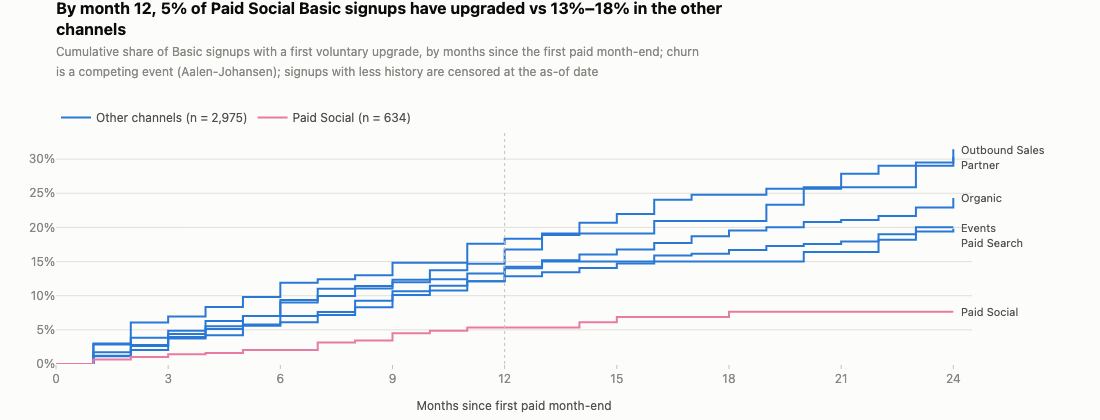

In [34]:
show(T.fig_time_to_upgrade('acquisition_channel'))

In [35]:
ttu_t = marts.load('transitions__time_to_upgrade')
ttu_t[(ttu_t.by == 'acquisition_channel') & ttu_t.k.isin([6, 12, 24])].pivot(index='group', columns='k', values=['cif_upgrade', 'cif_churn', 'at_risk'])

cif_upgrade               cif_churn                at_risk                  
k                       6      12     24        6      12     24       6        12       24
group                                                                                      
Events              0.0611 0.1424 0.2001    0.1334 0.2143 0.2893 168.0000 101.0000  27.0000
Organic             0.0902 0.1403 0.2432    0.1207 0.2411 0.3529 740.0000 440.0000 126.0000
Outbound Sales      0.1189 0.1835 0.3145    0.0572 0.1518 0.2189 163.0000 100.0000  26.0000
Paid Search         0.0703 0.1284 0.1979    0.1432 0.2635 0.4243 587.0000 365.0000 108.0000
Paid Social         0.0206 0.0535 0.0766    0.2853 0.4752 0.6049 300.0000  89.0000  25.0000
Partner             0.0936 0.1677 0.3036    0.0486 0.1061 0.2029 229.0000 149.0000  39.0000

In [36]:
md(f"""**Reading.** Upgrades accumulate steadily rather than in an early burst: Outbound Sales and Partner Basic signups reach {pct(ttu['Outbound Sales'], 0)} and {pct(ttu['Partner'], 0)} by month 12, Organic {pct(ttu['Organic'], 0)}, Paid Search {pct(ttu['Paid Search'], 0)}.
Paid Social reaches {pct(ttu['Paid Social'], 0)} — partly because it upgrades less, partly because {pct(chu['Paid Social'], 0)} of its signups have churned by month 12 (vs {pct(chu['Organic'], 0)} Organic), so few are left to upgrade. For Growth Marketing's 2027 plan this means a Paid Social account's value is its Basic MRR for as long as it stays, not expansion.
The curves start before the packaging change for most of their length; a cohort view of the post-April signups will only be readable from mid-2027.""")

**Reading.** Upgrades accumulate steadily rather than in an early burst: Outbound Sales and Partner Basic signups reach 18% and 17% by month 12, Organic 14%, Paid Search 13%.
Paid Social reaches 5% — partly because it upgrades less, partly because 48% of its signups have churned by month 12 (vs 24% Organic), so few are left to upgrade. For Growth Marketing's 2027 plan this means a Paid Social account's value is its Basic MRR for as long as it stays, not expansion.
The curves start before the packaging change for most of their length; a cohort view of the post-April signups will only be readable from mid-2027.

In [37]:
n_post_months = len(pd.period_range(T.POST_WINDOW[0], T.POST_WINDOW[1], freq='M'))
ps_up_post = int(table.set_index('cell').loc[T.PAID_SOCIAL, 'up_post'])
md(f"""## Limitations
- **Synthetic data**: effect sizes come from the generator's rules (`docs/data_model.md §6`); what transfers is the method — the decomposition, the intervals and the trigger logic — not the magnitudes.
- **Observational before / after.** The packaging change, the Paid Social program and the Technology slowdown overlap in time. The decomposition removes channel mix (and Technology as a check), but anything else that changed in spring 2026 is attributed to the packaging change. A holdout is the only clean test.
- **A drift predates the change.** The non-Paid-Social rate fell from {pct(mid_q.min(), 1)}–{pct(mid_q.max(), 1)} a month in Q2–Q3 2025 to {pct(late_q.min(), 1)}–{pct(late_q.max(), 1)} in Q4 2025 – Q1 2026 for reasons the data does not reveal, so the part of the fall that coincides with the change is a range (step net of trend to raw difference), not a point.
- **Small counts.** {k['voluntary_upgrades_post']} voluntary upgrades in the post window, {k['cs_save_downgrades_observed_6m']} CS saves with six months of follow-up, {ps_up_post} Paid Social upgrades in {n_post_months} months: every interval here is wide and the Paid Social series should not be read month by month.
- **{n_post_months} months of post-change data** for retention; the first annual renewals of post-change Basic cohorts are not observed until 2027.
- **No trial data** (scope §5): the conversion goal of the packaging change cannot be measured from billing data.
- **`change_source` is a label**, not an observed conversation: a "CS save" is a plan change the CSM keyed in after a cancellation request; a real billing system would be noisier.""")

## Limitations
- **Synthetic data**: effect sizes come from the generator's rules (`docs/data_model.md §6`); what transfers is the method — the decomposition, the intervals and the trigger logic — not the magnitudes.
- **Observational before / after.** The packaging change, the Paid Social program and the Technology slowdown overlap in time. The decomposition removes channel mix (and Technology as a check), but anything else that changed in spring 2026 is attributed to the packaging change. A holdout is the only clean test.
- **A drift predates the change.** The non-Paid-Social rate fell from 1.7%–2.1% a month in Q2–Q3 2025 to 1.3%–1.5% in Q4 2025 – Q1 2026 for reasons the data does not reveal, so the part of the fall that coincides with the change is a range (step net of trend to raw difference), not a point.
- **Small counts.** 73 voluntary upgrades in the post window, 43 CS saves with six months of follow-up, 5 Paid Social upgrades in 5 months: every interval here is wide and the Paid Social series should not be read month by month.
- **5 months of post-change data** for retention; the first annual renewals of post-change Basic cohorts are not observed until 2027.
- **No trial data** (scope §5): the conversion goal of the packaging change cannot be measured from billing data.
- **`change_source` is a label**, not an observed conversation: a "CS save" is a plan change the CSM keyed in after a cancellation request; a real billing system would be noisier.

In [38]:
rest = {c: v for c, v in ttu.items() if c != T.PAID_SOCIAL}
ratio = k['holdout_n_per_arm'] / k['holdout_n_per_arm_needed_80_power']
power_txt = ('enough for 80% power' if ratio >= 1 else
             ('slightly below' if ratio >= 0.85 else 'below') + f" the {k['holdout_n_per_arm_needed_80_power']:,.0f} per arm needed for 80% power (power ≈ {pct(k['holdout_power_at_n'], 0)})")
md(f"""## Recommendations (detail and sizing in `05_recommendations`)
1. **Product / Pricing — test before you revert.** The data clears the first half of the trigger (upgrade rate {pct(k['upgrade_rate_controlled_rel_change'], 0)} controlled for mix and Technology), and if the before / after change is put down to the packaging change the retention offset is at best {money(k['retained_basic_mrr_hi'])} per month against {money(-k['foregone_upgrade_mrr_per_month'])} of upgrade MRR.
   Rather than revert outright, run a **holdout**: re-gate advanced automations for a random 50% of new Basic self-serve signups for two quarters (about {k['holdout_n_per_arm']:,.0f} accounts per arm at the current {k['holdout_basic_signups_per_month']:,.0f} Basic signups per month). Primary metrics: 6-month cumulative voluntary upgrade rate and 6-month logo churn of the cohort.
   Under the old packaging {pct(k['holdout_p_old_6m'], 1)} of Basic signups upgraded within 6 months; if the post-change rate persists that becomes about {pct(k['holdout_p_new_6m'], 1)}, a gap of {k['holdout_gap_pts'] * 100:.1f} points. Two quarters give about {k['holdout_n_per_arm']:,.0f} accounts per arm, {power_txt}; the minimum detectable difference at 80% power is {k['holdout_mde_pts_80_power'] * 100:.1f} points, about the size of the expected {k['holdout_gap_pts'] * 100:.1f}-point gap. That is enough to confirm the direction and rough size of the upgrade effect, not to pin it down — and far too small to see a churn change of the size measured so far ({abs(k['basic_churn_non_ps_change_pts']) * 100:.2f} pts a month), which is why churn is read on the full Basic base instead. An "adjust" option (move a different Premium-only feature behind the gate) can be the gated arm instead of the old packaging.
2. **Growth Marketing — plan Paid Social on retention, not expansion.** By month 12, {pct(ttu[T.PAID_SOCIAL], 0)} of Paid Social Basic signups have upgraded against {pct(min(rest.values()), 0)}–{pct(max(rest.values()), 0)} in the other channels, and {pct(chu[T.PAID_SOCIAL], 0)} are gone within 12 months. Their payback model should carry Basic MRR only; onboarding should push the annual offer and the first-90-day activation, and the channel should be judged on 6- and 12-month revenue retention per $1 of first-month MRR (`01_metrics`), not on signups.
3. **Customer Success — keep the downgrade-to-save play, track it as contraction.** {pct(k['cs_save_paying_6m_share'], 0)} of saved accounts are still paying six months on, close to accounts that never asked to leave, but at {pct(k['cs_save_mrr_retained_share'], 0)} of their former MRR. Saves belong on the re-risk list with a 6-month check-in, and the save rate by CSM book is worth reporting monthly.

**What data I would want next:** trial and activation events (to measure the conversion goal of the packaging change directly); the holdout assignment log; paywall / gate-hit events after April (to see whether the remaining upgrade demand moved to analytics or the API — the candidate features for an "adjust" option); CRM notes on the Q4 2025 slowdown in upgrades, which the billing data cannot explain.""")

## Recommendations (detail and sizing in `05_recommendations`)
1. **Product / Pricing — test before you revert.** The data clears the first half of the trigger (upgrade rate −51% controlled for mix and Technology), and if the before / after change is put down to the packaging change the retention offset is at best $1.6K per month against $3.1K of upgrade MRR.
   Rather than revert outright, run a **holdout**: re-gate advanced automations for a random 50% of new Basic self-serve signups for two quarters (about 449 accounts per arm at the current 150 Basic signups per month). Primary metrics: 6-month cumulative voluntary upgrade rate and 6-month logo churn of the cohort.
   Under the old packaging 8.3% of Basic signups upgraded within 6 months; if the post-change rate persists that becomes about 4.0%, a gap of 4.3 points. Two quarters give about 449 accounts per arm, slightly below the 481 per arm needed for 80% power (power ≈ 77%); the minimum detectable difference at 80% power is 4.5 points, about the size of the expected 4.3-point gap. That is enough to confirm the direction and rough size of the upgrade effect, not to pin it down — and far too small to see a churn change of the size measured so far (0.14 pts a month), which is why churn is read on the full Basic base instead. An "adjust" option (move a different Premium-only feature behind the gate) can be the gated arm instead of the old packaging.
2. **Growth Marketing — plan Paid Social on retention, not expansion.** By month 12, 5% of Paid Social Basic signups have upgraded against 13%–18% in the other channels, and 48% are gone within 12 months. Their payback model should carry Basic MRR only; onboarding should push the annual offer and the first-90-day activation, and the channel should be judged on 6- and 12-month revenue retention per $1 of first-month MRR (`01_metrics`), not on signups.
3. **Customer Success — keep the downgrade-to-save play, track it as contraction.** 91% of saved accounts are still paying six months on, close to accounts that never asked to leave, but at 41% of their former MRR. Saves belong on the re-risk list with a 6-month check-in, and the save rate by CSM book is worth reporting monthly.

**What data I would want next:** trial and activation events (to measure the conversion goal of the packaging change directly); the holdout assignment log; paywall / gate-hit events after April (to see whether the remaining upgrade demand moved to analytics or the API — the candidate features for an "adjust" option); CRM notes on the Q4 2025 slowdown in upgrades, which the billing data cannot explain.